# 02 – Data cleaning and exploratory analysis

In [1]:
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv("data/books.csv")
print(df.shape)
df.head()

(175, 10)


,title,category,price,rating,availability,description,upc,url,image_url,image_path
0,Soumission,Fiction,£50.10,One,In stock (20 available),"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/ee/cf/e...,data/images/6957f44c3847a760.jpg
1,Private Paris (Private #10),Fiction,£47.61,Five,In stock (17 available),Paris is burning--and only Private's Jack Morg...,b12b89017878a60d,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/05/87/0...,data/images/b12b89017878a60d.jpg
2,"We Love You, Charlie Freeman",Fiction,£50.27,Five,In stock (16 available),"The Freeman family--Charles, Laurel, and their...",8d455c7539795d2a,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/87/a2/8...,data/images/8d455c7539795d2a.jpg
3,Thirst,Fiction,£17.27,Five,In stock (16 available),"On a searing summer Friday, Eddie Chapman has ...",709822d0b5bcb7f4,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/8c/54/8...,data/images/709822d0b5bcb7f4.jpg
4,The Murder That Never Was (Forensic Instincts #5),Fiction,£54.11,Three,In stock (16 available),"Given the opportunity, would you assume someon...",d01ac97e2b8947c2,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/29/e0/2...,data/images/d01ac97e2b8947c2.jpg


## 1. Structure and basic checks

Check data types, missing values and duplicates. The UPC is unique per book, so it is the
natural key for duplicates.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   title         175 non-null    str  
 1   category      175 non-null    str  
 2   price         175 non-null    str  
 3   rating        175 non-null    str  
 4   availability  175 non-null    str  
 5   description   175 non-null    str  
 6   upc           175 non-null    str  
 7   url           175 non-null    str  
 8   image_url     175 non-null    str  
 9   image_path    175 non-null    str  
dtypes: str(10)
memory usage: 13.8 KB


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate UPCs:", df["upc"].duplicated().sum())
print("Duplicate titles:", df["title"].duplicated().sum())

Missing values: 0
Duplicate UPCs: 0
Duplicate titles: 0


## 2. Convert raw text columns to numbers

The scraper stored values exactly as shown on the site. They are converted here:
- `price`: `"£50.10"` → `50.10`
- `rating`: `"Three"` → `3`
- `availability`: `"In stock (20 available)"` → `stock = 20`

In [4]:
RATINGS = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

df["price"] = df["price"].str.replace("£", "").astype(float)
df["rating"] = df["rating"].map(RATINGS)
# grab the number out of "In stock (20 available)"
df["stock"] = df["availability"].str.extract(r"(\d+)")[0].astype(int)
df = df.drop(columns="availability")

df[["price", "rating", "stock"]].describe()

,price,rating,stock
count,175.000000,175.000000,175.000000
mean,34.931143,2.994286,8.931429
std,14.369054,1.424325,5.367622
min,10.600000,1.000000,1.000000
25%,22.580000,2.000000,3.000000
50%,34.000000,3.000000,8.000000
75%,46.465000,4.000000,14.000000
max,59.980000,5.000000,20.000000


## 3. Clean the descriptions

Most descriptions contain the site's short teaser followed by the full text, and end with
`" ...more"`. Example: `"...sans vraie révolution, s Dans une France assez proche..."`.
The duplicated teaser would count the same words twice, so it is removed.

In [5]:
def clean_description(text):
    # Remove the "...more" link text at the end
    text = text.removesuffix("...more").strip()

    # Both the teaser and the full text start with the same words.
    # Look for the first 40 characters again, starting after position 0.
    start = text.find(text[:40], 1)

    # If found, the full text starts there, so drop the teaser before it
    if start > 0:
        text = text[start:]
    return text


print("Ending with '...more':", df["description"].str.endswith("...more").sum())
before = df["description"].str.len()
df["description"] = df["description"].apply(clean_description)
# a text counts as fixed if it got shorter by more than just the "...more" bit
print("Repeated teasers removed:", (df["description"].str.len() < before - 10).sum())
print("Average length before/after:", round(before.mean()), "/", round(df["description"].str.len().mean()))

Ending with '...more': 171
Repeated teasers removed: 168
Average length before/after: 1598 / 1229


## 4. Find non-English descriptions

A simple check: the share of words that are very common English words. Normal English text
scores around 0.25, a non-English text scores close to 0.

In [6]:
COMMON_EN = {"the", "and", "of", "to", "a", "in", "is", "that", "his", "her", "with", "for"}

def english_ratio(text):
    words = re.findall(r"[a-z]+", text.lower())
    # max(..., 1) so we never divide by zero on an empty text
    return sum(w in COMMON_EN for w in words) / max(len(words), 1)

df["en_ratio"] = df["description"].apply(english_ratio)
df.sort_values("en_ratio")[["title", "category", "en_ratio", "description"]].head(4)

,title,category,en_ratio,description
0,Soumission,Fiction,0.000000,"Dans une France assez proche de la nôtre, un h..."
169,Kindle Paperwhite User's Guide,Nonfiction,0.000000,Kindle Paperwhite User's Guide
100,Eaternity: More than 150 Deliciously Easy Vega...,Nonfiction,0.153310,Vegan chef and wellness expert Jason Wrobel of...
110,"Mother, Can You Not?",Nonfiction,0.166667,Based on the wildly popular Instagram account ...


Only *Soumission* (French) is not English. The *Kindle Paperwhite User's Guide* also scores 0,
but only because its description is just the title, so it stays.
*Soumission* is removed: its French words would never match the English vocabulary of the other books.

In [7]:
# reset_index renumbers the rows 0, 1, 2... after removing one
df = df[df["title"] != "Soumission"].drop(columns="en_ratio").reset_index(drop=True)
print(df.shape)

(174, 10)


## 5. Check the images

Every image must open without errors (a broken file would raise an error here).
Sizes differ, which matters for the image features: they are built so that the size doesn't affect them (see notebook 03).

In [8]:
widths, heights = [], []
for path in df["image_path"]:
    with Image.open(path) as img:
        widths.append(img.width)
        heights.append(img.height)

print("Images opened:", len(widths))
print(f"Width: {min(widths)}–{max(widths)} px, height: {min(heights)}–{max(heights)} px")

Images opened: 174
Width: 115–318 px, height: 175–400 px


## 6. Target label

Fiction = 1, Nonfiction = 0. The classes are imbalanced, so always guessing "Nonfiction" is the
baseline the model needs to beat.

In [9]:
df["is_fiction"] = (df["category"] == "Fiction").astype(int)

counts = df["category"].value_counts()
print(counts)
print(f"Majority baseline accuracy: {counts.max() / counts.sum():.1%}")

category
Nonfiction    110
Fiction        64
Name: count, dtype: int64
Majority baseline accuracy: 63.2%


## 7. Exploratory analysis

The analysis uses a copy (`eda`), so the extra columns made here are not saved with the cleaned data.

### Numeric columns by category
The site states that prices and ratings were randomly assigned, so we expect no real difference.

In [10]:
eda = df.copy()
eda["desc_length"] = eda["description"].str.split().str.len()
eda["title_length"] = eda["title"].str.split().str.len()

eda.groupby("category")[["price", "rating", "stock", "desc_length", "title_length"]].mean().round(2)

,price,rating,stock,desc_length,title_length
category,,,,,
Fiction,35.85,3.22,8.88,181.48,3.75
Nonfiction,34.26,2.88,8.86,213.15,9.41


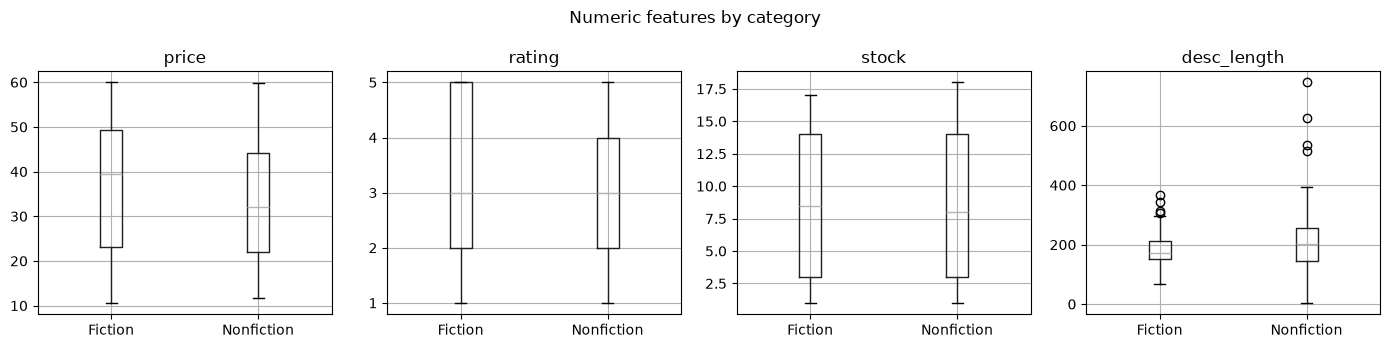

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, ["price", "rating", "stock", "desc_length"]):
    eda.boxplot(column=col, by="category", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Numeric features by category")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/numeric_by_category.png", dpi=150)
plt.show()

### Title patterns
Nonfiction titles often have a subtitle after a colon ("Sapiens: A Brief History of Humankind"),
while fiction titles often belong to a series ("Private Paris (Private #10)").

In [12]:
eda["title_has_colon"] = eda["title"].str.contains(":")
eda["title_has_series"] = eda["title"].str.contains("#")

eda.groupby("category")[["title_has_colon", "title_has_series"]].mean().round(2)

,title_has_colon,title_has_series
category,,
Fiction,0.02,0.27
Nonfiction,0.71,0.05


### Most common words in the descriptions per category
English stop words ("the", "and", ...) are removed, since they appear everywhere.

In [13]:
vectorizer = CountVectorizer(stop_words="english")

for category in ["Fiction", "Nonfiction"]:
    texts = df.loc[df["category"] == category, "description"]
    # count each word per book, then add the counts up over all books in this category
    word_counts = vectorizer.fit_transform(texts).toarray().sum(axis=0)
    words = pd.Series(word_counts, index=vectorizer.get_feature_names_out())
    print(category + ":", ", ".join(words.nlargest(15).index))

Fiction: life, love, new, family, novel, world, young, story, woman, old, home, man, secrets, years, daughter
Nonfiction: life, new, book, world, time, people, way, love, america, lives, author, years, like, work, american


## 8. Save the cleaned data

Engineered features are created in the next notebook.

In [14]:
df.to_csv("data/books_clean.csv", index=False, encoding="utf-8")
print(df.shape)
df.head()

(174, 11)


,title,category,price,rating,description,upc,url,image_url,image_path,stock,is_fiction
0,Private Paris (Private #10),Fiction,47.61,5,Paris is burning--and only Private's Jack Morg...,b12b89017878a60d,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/05/87/0...,data/images/b12b89017878a60d.jpg,17,1
1,"We Love You, Charlie Freeman",Fiction,50.27,5,"The Freeman family--Charles, Laurel, and their...",8d455c7539795d2a,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/87/a2/8...,data/images/8d455c7539795d2a.jpg,16,1
2,Thirst,Fiction,17.27,5,"On a searing summer Friday, Eddie Chapman has ...",709822d0b5bcb7f4,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/8c/54/8...,data/images/709822d0b5bcb7f4.jpg,16,1
3,The Murder That Never Was (Forensic Instincts #5),Fiction,54.11,3,"Given the opportunity, would you assume someon...",d01ac97e2b8947c2,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/29/e0/2...,data/images/d01ac97e2b8947c2.jpg,16,1
4,Tuesday Nights in 1980,Fiction,21.04,2,"“In one sentence, Ms. Prentiss captures a sens...",b8736690cf263a3c,https://books.toscrape.com/catalogue/tuesday-n...,https://books.toscrape.com/media/cache/a3/ad/a...,data/images/b8736690cf263a3c.jpg,15,1
